# Notebook 2: Fine tuning transformer models for Kinyarwanda news topic classification

This notebook fine tunes pretrained transformer models on the same cleaned data that the baseline used (saved by notebook 1), compares them with the baseline, analyzes their errors, and prepares the best model for the web app.

Before you start:
1. Use a GPU: Runtime, then Change runtime type, then T4 GPU.
2. Notebook 1 must have finished, because this notebook reads the files it saved in Google Drive.

How this notebook is organized:
1. Setup and loading the data
2. Fresh start: removes the results of any older run of this notebook, so nothing is duplicated
3. How long the articles are in tokens
4. Training code, explained step by step
5. Five experiments (T1 to T5). About 75 minutes in total on a T4 GPU.
6. Comparison with the baseline, per topic scores, and error analysis
7. Choosing the model for the app, and uploading it to Hugging Face (optional, set a switch first)

If Colab disconnects, reconnect and run the cells again from the top. The fresh start cell notices that a run is already in progress and does not delete anything. Finished experiments are skipped, so only the unfinished one trains again.

How the training works in simple words:
1. A pretrained model already knows a lot about the language from reading large amounts of text.
2. I add a small classification layer on top that has 14 outputs, one for each topic.
3. I train the whole model for a few epochs on my labeled articles, so it learns the task.
4. After every epoch I score it on the validation set. I keep the best epoch.
5. At the end I score the best epoch on the test set one time. Choices between models are made on the validation set only, never on the test set.

I wrote the training loop by hand in PyTorch instead of using a ready made trainer, so every step is visible and I can explain it.

## 1. Setup

In [2]:
!pip install -q transformers sentencepiece huggingface_hub

In [3]:
import os, json, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          get_linear_schedule_with_warmup)
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/kinyarwanda_news_project"
except ImportError:
    PROJECT_DIR = "./kinyarwanda_news_project"

MODEL_DIR = os.path.join(PROJECT_DIR, "transformer_runs")
os.makedirs(MODEL_DIR, exist_ok=True)

# False saves only the small best model file after each run. A run that is cut off
# then starts again from the beginning, but finished runs are still skipped.
# True also saves a very large training state after every epoch so a cut off run can resume.
SAVE_RESUME_STATE = False

device = "cuda" if torch.cuda.is_available() else "cpu"
use_amp = device == "cuda"
print("Device:", device)
if device == "cpu":
    print("No GPU found. Training on CPU will be far too slow. Change the runtime type to T4 GPU.")
else:
    print("GPU:", torch.cuda.get_device_name(0))

Mounted at /content/drive
Device: cuda
GPU: Tesla T4


## 2. Load the data from notebook 1

These are the cleaned and deduplicated splits. Using exactly the same splits as the baseline makes the comparison fair.

In [4]:
train_df = pd.read_csv(os.path.join(PROJECT_DIR, "train.csv"))
val_df = pd.read_csv(os.path.join(PROJECT_DIR, "val.csv"))
test_df = pd.read_csv(os.path.join(PROJECT_DIR, "test.csv"))
for d in (train_df, val_df, test_df):
    d["text"] = d["text"].fillna("").astype(str)

LABEL_NAMES = ["politics", "sport", "economy", "health", "entertainment", "history",
               "technology", "tourism", "culture", "fashion", "religion",
               "environment", "education", "relationship"]
NUM_LABELS = len(LABEL_NAMES)

print("Train:", len(train_df), " Validation:", len(val_df), " Test:", len(test_df))

with open(os.path.join(PROJECT_DIR, "baseline_summary.json")) as f:
    baseline = json.load(f)
print("Baseline to beat:", baseline["best_baseline"],
      " test accuracy", baseline["test_accuracy"], " test macro F1", baseline["test_macro_f1"])

Train: 8069  Validation: 897  Test: 2027
Baseline to beat: B5 char 3-5gram + LinearSVM balanced  test accuracy 0.7982  test macro F1 0.7189


## 3. Fresh start

This cell removes the results of any older run of this notebook, so the tables in this run are complete and consistent and no old files are mixed in. It deletes only:
1. the folder `transformer_runs` (all older experiment results and model files)
2. the output files of this notebook that are listed in the cell

It never touches `train.csv`, `val.csv`, `test.csv`, or any of the baseline files from notebook 1.

When Colab deletes files in Drive they go to the Drive Bin, and they still count against your storage until you empty the Bin. Empty it after this cell runs.

A small marker file records that a fresh run has started. If the marker exists, the cell does nothing, so a reconnect in the middle of a run cannot delete finished experiments. To start completely over, set `FORCE_CLEAN = True` and run the cell once.

In [5]:
import shutil

FORCE_CLEAN = False

MARKER = os.path.join(PROJECT_DIR, "transformer_run_started.txt")
OWN_OUTPUT_FILES = ["model_comparison.csv", "training_curves.png", "token_length_stats.json",
                    "token_length_histogram.png", "per_topic_f1_comparison.csv",
                    "error_examples.csv", "model_agreement_summary.json",
                    "deployment_model.json"]

# Safety check so that only the expected folders can ever be deleted
assert PROJECT_DIR.endswith("kinyarwanda_news_project")
assert MODEL_DIR == os.path.join(PROJECT_DIR, "transformer_runs")

if os.path.exists(MARKER) and not FORCE_CLEAN:
    print("A fresh run is already in progress, so nothing was deleted.")
    print("Started:", open(MARKER).read().strip())
else:
    if os.path.exists(MODEL_DIR):
        for folder in sorted(os.listdir(MODEL_DIR)):
            print("Removing old run folder:", folder)
        shutil.rmtree(MODEL_DIR)
    for name in OWN_OUTPUT_FILES:
        path = os.path.join(PROJECT_DIR, name)
        if os.path.exists(path):
            os.remove(path)
            print("Removing old file:", name)
    os.makedirs(MODEL_DIR, exist_ok=True)
    with open(MARKER, "w") as f:
        f.write(time.strftime("%Y-%m-%d %H:%M:%S"))
    print("Fresh start done. Now empty the Drive Bin to get the space back.")

A fresh run is already in progress, so nothing was deleted.
Started: 2026-10-15 07:25:48


## 4. How long are the articles in tokens?

A Transformer reads a fixed number of tokens at most. Tokens are word pieces, and Kinyarwanda words are often split into several pieces, so the token count is higher than the word count. I measure it with the AfroXLMR tokenizer, so that the maximum length I choose is based on evidence. The result also goes into the limitations section of the report.

config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/398 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (696 > 512). Running this sequence through the model will result in indexing errors


{
  "articles": 8069,
  "median_tokens": 589,
  "p75_tokens": 852,
  "p90_tokens": 1205,
  "p95_tokens": 1563,
  "share_over_128_percent": 98.0,
  "share_over_256_percent": 93.2,
  "share_over_512_percent": 60.3
}


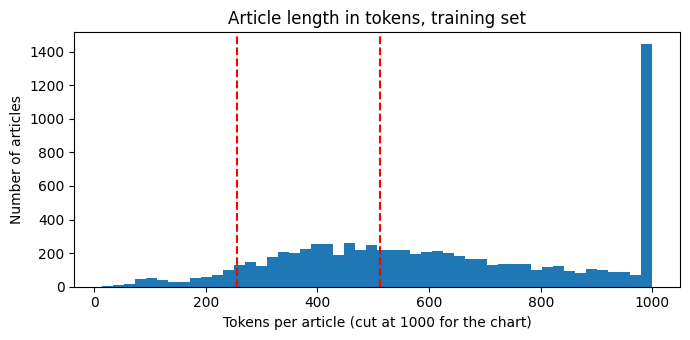

In [6]:
tok_check = AutoTokenizer.from_pretrained("Davlan/afro-xlmr-base")
lengths = np.array([len(x) for x in tok_check(train_df["text"].tolist())["input_ids"]])

stats = {"articles": int(len(lengths)),
         "median_tokens": int(np.median(lengths)),
         "p75_tokens": int(np.percentile(lengths, 75)),
         "p90_tokens": int(np.percentile(lengths, 90)),
         "p95_tokens": int(np.percentile(lengths, 95)),
         "share_over_128_percent": round(float((lengths > 128).mean() * 100), 1),
         "share_over_256_percent": round(float((lengths > 256).mean() * 100), 1),
         "share_over_512_percent": round(float((lengths > 512).mean() * 100), 1)}
print(json.dumps(stats, indent=2))
with open(os.path.join(PROJECT_DIR, "token_length_stats.json"), "w") as f:
    json.dump(stats, f, indent=2)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(np.clip(lengths, 0, 1000), bins=50)
for limit in (256, 512):
    ax.axvline(limit, color="red", linestyle="--")
ax.set_xlabel("Tokens per article (cut at 1000 for the chart)")
ax.set_ylabel("Number of articles")
ax.set_title("Article length in tokens, training set")
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_DIR, "token_length_histogram.png"), dpi=150)
plt.show()

## 5. Training and evaluation functions

What each part does:

**Tokenizer.** Turns text into pieces from the model's own vocabulary (sub words) and then into numbers. Long articles are cut at `max_len` tokens, because the model can only read a limited length and longer inputs use much more memory.

**Batches.** The model sees 16 articles at a time. Shorter articles in a batch are padded so they all have the same length, and an attention mask tells the model to ignore the padding.

**Loss.** Cross entropy compares the model's predicted topic probabilities with the true topic. In one experiment I give small topics a larger weight, because the dataset is unbalanced.

**Optimizer.** AdamW updates the weights. A small learning rate (2e-5) is used because the model is already trained and I only want to adjust it gently. The learning rate rises during the first 10 percent of steps (warmup) and then falls linearly to zero.

**Mixed precision.** On the GPU, most math runs in 16 bit numbers, which is faster and uses less memory. A gradient scaler keeps small gradients from rounding to zero. Gradients are also clipped to a norm of 1.0 so one bad batch cannot break training.

**Saving.** After every epoch the model is scored on the validation set. The weights of the best epoch are kept in memory and written to Google Drive once, when the run ends, together with the results file. A run that was cut off by a disconnect starts again from the beginning, and finished runs are skipped.

In [7]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def encode(df, tokenizer, max_len):
    enc = tokenizer(df["text"].tolist(), truncation=True, max_length=max_len)
    return [{"input_ids": ids, "label": int(y)} for ids, y in zip(enc["input_ids"], df["label"])]


def make_collate(pad_id):
    def collate(batch):
        longest = max(len(item["input_ids"]) for item in batch)
        ids = torch.full((len(batch), longest), pad_id, dtype=torch.long)
        mask = torch.zeros((len(batch), longest), dtype=torch.long)
        for i, item in enumerate(batch):
            n = len(item["input_ids"])
            ids[i, :n] = torch.tensor(item["input_ids"])
            mask[i, :n] = 1
        labels = torch.tensor([item["label"] for item in batch], dtype=torch.long)
        return ids, mask, labels
    return collate


@torch.no_grad()
def predict(model, loader):
    model.eval()
    all_probs = []
    for ids, mask, _ in loader:
        ids, mask = ids.to(device), mask.to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            logits = model(input_ids=ids, attention_mask=mask).logits
        all_probs.append(torch.softmax(logits.float(), dim=-1).cpu().numpy())
    return np.concatenate(all_probs)


def scores(y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"accuracy": round(float(accuracy_score(y_true, y_pred)), 4),
            "macro_precision": round(float(p), 4),
            "macro_recall": round(float(r), 4),
            "macro_f1": round(float(f1), 4)}

In [8]:
def run_experiment(name, model_name, max_len=256, lr=2e-5, epochs=3, batch_size=16,
                   weighted_loss=False, seed=42):
    exp_dir = os.path.join(MODEL_DIR, name)
    os.makedirs(exp_dir, exist_ok=True)
    result_path = os.path.join(exp_dir, "result.json")
    if os.path.exists(result_path):
        print(name, "is already finished. Loading the saved result.")
        with open(result_path) as f:
            return json.load(f)

    set_seed(seed)
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    train_data = encode(train_df, tokenizer, max_len)
    val_data = encode(val_df, tokenizer, max_len)
    test_data = encode(test_df, tokenizer, max_len)
    cut = np.mean([len(x["input_ids"]) >= max_len for x in train_data])
    print("Share of training articles cut at", max_len, "tokens:", round(float(cut) * 100, 1), "%")

    collate = make_collate(tokenizer.pad_token_id)
    g = torch.Generator()
    g.manual_seed(seed)
    train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True,
                              collate_fn=collate, generator=g)
    val_loader = DataLoader(val_data, batch_size=64, shuffle=False, collate_fn=collate)
    test_loader = DataLoader(test_data, batch_size=64, shuffle=False, collate_fn=collate)

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=NUM_LABELS,
        id2label=dict(enumerate(LABEL_NAMES)), label2id={n: i for i, n in enumerate(LABEL_NAMES)})
    model.to(device)

    no_decay = ("bias", "LayerNorm.weight")
    params = [
        {"params": [p for n, p in model.named_parameters() if not any(k in n for k in no_decay)],
         "weight_decay": 0.01},
        {"params": [p for n, p in model.named_parameters() if any(k in n for k in no_decay)],
         "weight_decay": 0.0},
    ]
    optimizer = torch.optim.AdamW(params, lr=lr)
    total_steps = epochs * len(train_loader)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    if weighted_loss:
        counts = np.bincount(train_df["label"], minlength=NUM_LABELS)
        weights = len(train_df) / (NUM_LABELS * counts)
        class_weights = torch.tensor(weights, dtype=torch.float).to(device)
    else:
        class_weights = None
    loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights)

    state_path = os.path.join(exp_dir, "last_state.pt")
    best_path = os.path.join(exp_dir, "best_model.pt")
    start_epoch, history, best_f1 = 0, [], -1.0
    best_half = None
    if os.path.exists(state_path):
        state = torch.load(state_path, map_location=device, weights_only=False)
        model.load_state_dict(state["model"])
        optimizer.load_state_dict(state["optimizer"])
        scheduler.load_state_dict(state["scheduler"])
        scaler.load_state_dict(state["scaler"])
        start_epoch, history, best_f1 = state["epoch"], state["history"], state["best_f1"]
        print("Resuming after epoch", start_epoch)

    y_val = val_df["label"].values
    run_start = time.time()
    for epoch in range(start_epoch, epochs):
        model.train()
        running, n_seen = 0.0, 0
        for step, (ids, mask, labels) in enumerate(train_loader, start=1):
            ids, mask, labels = ids.to(device), mask.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                logits = model(input_ids=ids, attention_mask=mask).logits
            loss = loss_fn(logits.float(), labels)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            running += loss.item() * len(labels)
            n_seen += len(labels)
            if step % 100 == 0:
                print("  epoch", epoch + 1, "step", step, "of", len(train_loader),
                      "average loss", round(running / n_seen, 4))

        val_probs = predict(model, val_loader)
        val_scores = scores(y_val, val_probs.argmax(axis=1))
        row = {"epoch": epoch + 1, "train_loss": round(running / n_seen, 4),
               **{"val_" + k: v for k, v in val_scores.items()}}
        history.append(row)
        print(row, " minutes so far:", round((time.time() - run_start) / 60, 1))

        if val_scores["macro_f1"] > best_f1:
            best_f1 = val_scores["macro_f1"]
            # Keep the best weights in memory and write them to Drive once, after training.
            # This avoids many large writes to Drive during the run.
            best_half = {k: (v.half() if v.is_floating_point() else v).detach().cpu().clone()
                         for k, v in model.state_dict().items()}
        if SAVE_RESUME_STATE:
            torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                        "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                        "epoch": epoch + 1, "history": history, "best_f1": best_f1}, state_path)

    if best_half is not None:
        torch.save(best_half, best_path)
        del best_half

    # Load the best epoch and score it on the test set one time
    best_state = torch.load(best_path, map_location=device)
    model.load_state_dict({k: v.float() if v.is_floating_point() else v
                           for k, v in best_state.items()})
    test_probs = predict(model, test_loader)
    test_pred = test_probs.argmax(axis=1)
    y_test = test_df["label"].values
    test_scores = scores(y_test, test_pred)

    print()
    print(name, "test scores:", test_scores)
    print(classification_report(y_test, test_pred, target_names=LABEL_NAMES, digits=3,
                                zero_division=0))

    cm = confusion_matrix(y_test, test_pred, labels=range(NUM_LABELS))
    fig, ax = plt.subplots(figsize=(10, 9))
    ConfusionMatrixDisplay(cm, display_labels=LABEL_NAMES).plot(ax=ax, xticks_rotation=60,
                                                               colorbar=False)
    ax.set_title("Confusion matrix on the test set: " + name)
    plt.tight_layout()
    plt.savefig(os.path.join(exp_dir, "confusion_matrix.png"), dpi=150)
    plt.show()

    preds = pd.DataFrame({"row": np.arange(len(test_df)),
                          "true": [LABEL_NAMES[i] for i in y_test],
                          "predicted": [LABEL_NAMES[i] for i in test_pred],
                          "confidence": test_probs.max(axis=1).round(4)})
    preds.to_csv(os.path.join(exp_dir, "test_predictions.csv"), index=False)

    best_epoch = int(max(history, key=lambda r: r["val_macro_f1"])["epoch"])
    result = {"name": name, "model": model_name, "max_len": max_len, "lr": lr, "epochs": epochs,
              "batch_size": batch_size, "weighted_loss": weighted_loss, "best_epoch": best_epoch,
              "best_val_macro_f1": best_f1,
              **{"test_" + k: v for k, v in test_scores.items()},
              "train_minutes": round((time.time() - run_start) / 60, 1),
              "history": history}
    with open(result_path, "w") as f:
        json.dump(result, f, indent=2)

    if os.path.exists(state_path):
        os.remove(state_path)

    del model, optimizer
    if device == "cuda":
        torch.cuda.empty_cache()
    return result

## 6. Experiments

The research questions:

| Name | Question it answers | What changes |
|---|---|---|
| T1 | Does fine tuning a pretrained African language model come close to or beat the baseline? | AfroXLMR base, 3 epochs, max length 256 |
| T2 | Does a class weighted loss help the small topics, as it did for the baseline (B5)? | same as T1, plus class weights |
| T3 | Does a model that was not adapted to African languages do as well? | XLM-R base instead of AfroXLMR base |
| T4 | Is the larger model worth it? | AfroXLMR small instead of base |
| T5 | Was 3 epochs too short? | same as T1, but 8 epochs |

All runs use the same data, the same seed (42), and the same other settings. I use one seed because of time, so small differences between runs should not be read as proof.

Each experiment is its own cell. Approximate time on a T4 GPU: T1 10 minutes, T2 10, T3 15, T4 12, T5 25 to 30.

In [9]:
r1 = run_experiment("T1_afroxlmr_base", "Davlan/afro-xlmr-base")

T1_afroxlmr_base is already finished. Loading the saved result.


In [10]:
r2 = run_experiment("T2_afroxlmr_base_weighted", "Davlan/afro-xlmr-base", weighted_loss=True)

T2_afroxlmr_base_weighted is already finished. Loading the saved result.


In [11]:
r3 = run_experiment("T3_xlmr_base", "FacebookAI/xlm-roberta-base")

T3_xlmr_base is already finished. Loading the saved result.


In [12]:
r4 = run_experiment("T4_afroxlmr_small", "Davlan/afro-xlmr-small")

T4_afroxlmr_small is already finished. Loading the saved result.


In [13]:
r5 = run_experiment("T5_afroxlmr_base_8epochs", "Davlan/afro-xlmr-base", epochs=8)

T5_afroxlmr_base_8epochs is already finished. Loading the saved result.


Share of training articles cut at 512 tokens: 60.5 %


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1 step 100 of 505 average loss 2.4138
  epoch 1 step 200 of 505 average loss 1.9191
  epoch 1 step 300 of 505 average loss 1.6509
  epoch 1 step 400 of 505 average loss 1.4834
  epoch 1 step 500 of 505 average loss 1.3733
{'epoch': 1, 'train_loss': 1.369, 'val_accuracy': 0.7458, 'val_macro_precision': 0.6036, 'val_macro_recall': 0.4791, 'val_macro_f1': 0.4985}  minutes so far: 4.5
  epoch 2 step 100 of 505 average loss 0.7757
  epoch 2 step 200 of 505 average loss 0.7716
  epoch 2 step 300 of 505 average loss 0.7595
  epoch 2 step 400 of 505 average loss 0.7546
  epoch 2 step 500 of 505 average loss 0.7442
{'epoch': 2, 'train_loss': 0.7421, 'val_accuracy': 0.7837, 'val_macro_precision': 0.7423, 'val_macro_recall': 0.6386, 'val_macro_f1': 0.6686}  minutes so far: 9.2
  epoch 3 step 100 of 505 average loss 0.6337
  epoch 3 step 200 of 505 average loss 0.6149
  epoch 3 step 300 of 505 average loss 0.6014
  epoch 3 step 400 of 505 average loss 0.5958
  epoch 3 step 500 of 505 avera

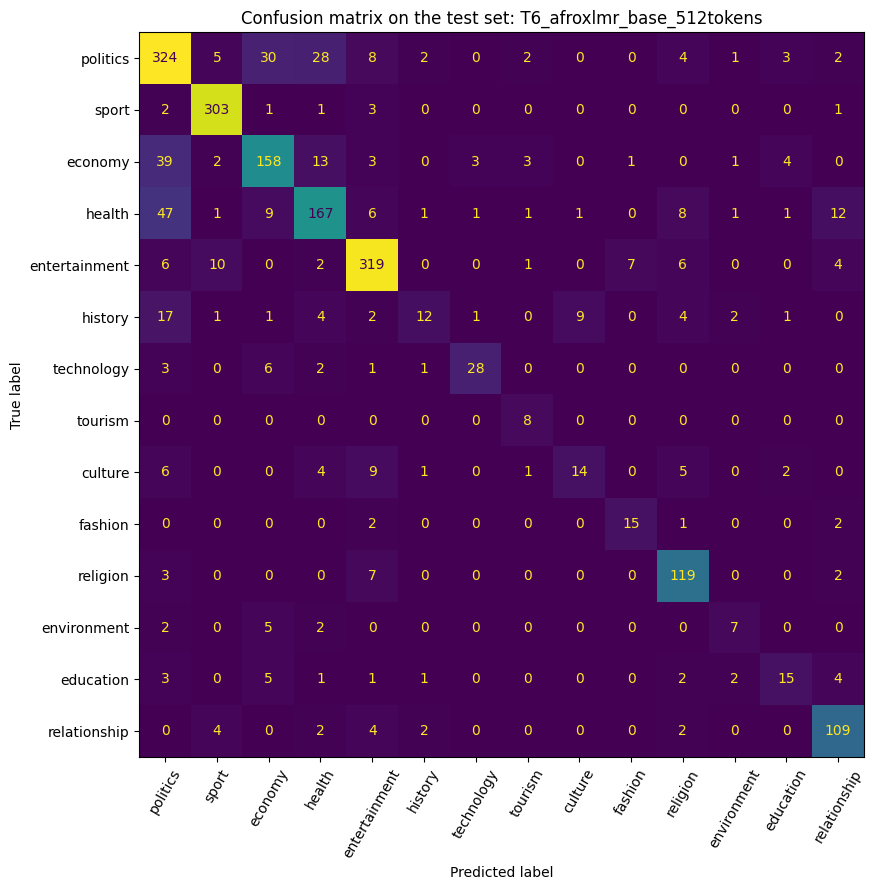

In [14]:
r6 = run_experiment("T6_afroxlmr_base_512tokens", "Davlan/afro-xlmr-base", max_len=512)

## 7. Compare everything

The table puts the baseline and all fine tuned models side by side. `val_macro_f1` is used to choose between models. The test columns are only for reporting.

In [15]:
base_val = pd.read_csv(os.path.join(PROJECT_DIR, "baseline_results_validation.csv"))
base_val_f1 = float(base_val.loc[base_val["experiment"] == baseline["best_baseline"],
                                 "val_macro_f1"].iloc[0])

rows = [{"name": "Baseline " + baseline["best_baseline"], "model": "TF-IDF + linear SVM",
         "epochs": None, "val_macro_f1": base_val_f1,
         "test_accuracy": baseline["test_accuracy"],
         "test_macro_precision": baseline["test_macro_precision"],
         "test_macro_recall": baseline["test_macro_recall"],
         "test_macro_f1": baseline["test_macro_f1"],
         "best_epoch": None, "train_minutes": None}]

histories = {}
for folder in sorted(os.listdir(MODEL_DIR)):
    path = os.path.join(MODEL_DIR, folder, "result.json")
    if os.path.exists(path):
        with open(path) as f:
            res = json.load(f)
        histories[res["name"]] = res["history"]
        rows.append({"name": res["name"], "model": res["model"], "epochs": res["epochs"],
                     "val_macro_f1": res["best_val_macro_f1"],
                     "test_accuracy": res["test_accuracy"],
                     "test_macro_precision": res["test_macro_precision"],
                     "test_macro_recall": res["test_macro_recall"],
                     "test_macro_f1": res["test_macro_f1"],
                     "best_epoch": res["best_epoch"], "train_minutes": res["train_minutes"]})

comparison = pd.DataFrame(rows)
comparison.to_csv(os.path.join(PROJECT_DIR, "model_comparison.csv"), index=False)

runs_only = comparison[comparison["name"].str.startswith("T")]
best_run = runs_only.sort_values("val_macro_f1", ascending=False).iloc[0]["name"]
print("Best fine tuned run on the validation set:", best_run)
comparison

Best fine tuned run on the validation set: T1_afroxlmr_base


,name,model,epochs,val_macro_f1,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,best_epoch,train_minutes
0,Baseline B5 char 3-5gram + LinearSVM balanced,TF-IDF + linear SVM,NaN,0.7324,0.7982,0.7166,0.7381,0.7189,NaN,NaN
1,T1_afroxlmr_base,Davlan/afro-xlmr-base,3.0,0.6890,0.7834,0.7058,0.6731,0.6666,3.0,7.8
2,T2_afroxlmr_base_weighted,Davlan/afro-xlmr-base,3.0,0.6620,0.7593,0.6368,0.7287,0.6657,3.0,7.8
3,T3_xlmr_base,FacebookAI/xlm-roberta-base,3.0,0.4602,0.6877,0.5375,0.4490,0.4573,3.0,7.7
4,T4_afroxlmr_small,Davlan/afro-xlmr-small,3.0,0.6049,0.7716,0.6728,0.6317,0.6337,3.0,6.2
5,T5_afroxlmr_base_8epochs,Davlan/afro-xlmr-base,8.0,0.6847,0.7745,0.6813,0.6838,0.6762,5.0,20.3
6,T6_afroxlmr_base_512tokens,Davlan/afro-xlmr-base,3.0,0.6846,0.7884,0.7032,0.6911,0.6800,3.0,14.3


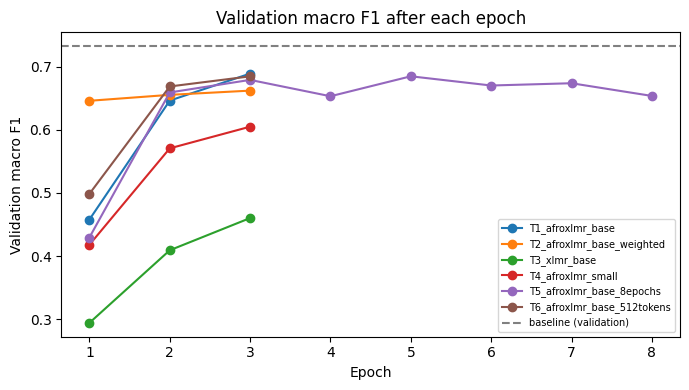

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, hist in histories.items():
    ax.plot([h["epoch"] for h in hist], [h["val_macro_f1"] for h in hist], marker="o", label=name)
ax.axhline(base_val_f1, color="gray", linestyle="--", label="baseline (validation)")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation macro F1")
ax.set_title("Validation macro F1 after each epoch")
ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_DIR, "training_curves.png"), dpi=150)
plt.show()

## 8. Scores per topic

Overall scores can hide what happens on small topics. This table shows the F1 score of the baseline and of every fine tuned run for each topic, sorted by how many test articles the topic has.

In [17]:
y_test = test_df["label"].values
name_to_id = {n: i for i, n in enumerate(LABEL_NAMES)}

base_pred_df = pd.read_csv(os.path.join(PROJECT_DIR, "baseline_test_predictions.csv"))
assert len(base_pred_df) == len(test_df), "Test sets do not match. Run notebook 1 again."
assert (base_pred_df["label_name"].values == test_df["label_name"].values).all()
base_ids = base_pred_df["predicted"].map(name_to_id).values

run_preds = {}
for name in histories:
    pdf = pd.read_csv(os.path.join(MODEL_DIR, name, "test_predictions.csv"))
    assert len(pdf) == len(test_df)
    run_preds[name] = pdf


def f1_by_topic(pred_ids):
    _, _, f1, _ = precision_recall_fscore_support(y_test, pred_ids, labels=range(NUM_LABELS),
                                                  zero_division=0)
    return f1.round(3)


per_topic = pd.DataFrame({"topic": LABEL_NAMES,
                          "test_articles": np.bincount(y_test, minlength=NUM_LABELS),
                          "baseline": f1_by_topic(base_ids)})
for name, pdf in run_preds.items():
    per_topic[name.split("_")[0]] = f1_by_topic(pdf["predicted"].map(name_to_id).values)
per_topic = per_topic.sort_values("test_articles", ascending=False).reset_index(drop=True)
per_topic.to_csv(os.path.join(PROJECT_DIR, "per_topic_f1_comparison.csv"), index=False)
per_topic

,topic,test_articles,baseline,T1,T2,T3,T4,T5,T6
0,politics,409,0.744,0.757,0.700,0.651,0.735,0.728,0.753
1,entertainment,355,0.880,0.882,0.859,0.835,0.883,0.881,0.886
2,sport,311,0.951,0.946,0.945,0.916,0.945,0.939,0.951
3,health,256,0.718,0.675,0.656,0.519,0.677,0.670,0.693
4,economy,227,0.724,0.733,0.714,0.585,0.700,0.739,0.715
5,religion,131,0.893,0.821,0.811,0.717,0.816,0.831,0.844
6,relationship,123,0.843,0.839,0.829,0.755,0.850,0.822,0.842
7,history,54,0.527,0.261,0.375,0.000,0.269,0.412,0.324
8,culture,42,0.632,0.500,0.625,0.148,0.475,0.605,0.424
9,technology,41,0.684,0.694,0.674,0.521,0.613,0.639,0.757


## 9. Error analysis

Here I compare the best fine tuned run (chosen on the validation set) with the baseline on the same test articles. I look at where they agree, which topics get confused, and at real examples of right and wrong predictions. These tables and examples are the material for the error analysis in the report and the video.

In [18]:
best_pdf = run_preds[best_run]
t_ids = best_pdf["predicted"].map(name_to_id).values
t_ok = t_ids == y_test
b_ok = base_ids == y_test

agreement = {"best_fine_tuned_run": best_run,
             "both_correct": int((t_ok & b_ok).sum()),
             "both_wrong": int((~t_ok & ~b_ok).sum()),
             "only_baseline_correct": int((b_ok & ~t_ok).sum()),
             "only_fine_tuned_correct": int((t_ok & ~b_ok).sum()),
             "test_articles": int(len(y_test))}
print(json.dumps(agreement, indent=2))
with open(os.path.join(PROJECT_DIR, "model_agreement_summary.json"), "w") as f:
    json.dump(agreement, f, indent=2)

cm = confusion_matrix(y_test, t_ids, labels=range(NUM_LABELS))
pairs = [(LABEL_NAMES[i] + " predicted as " + LABEL_NAMES[j], int(cm[i, j]))
         for i in range(NUM_LABELS) for j in range(NUM_LABELS) if i != j and cm[i, j] > 0]
print()
print("Most common confusions of", best_run)
pd.DataFrame(sorted(pairs, key=lambda x: -x[1])[:10], columns=["confusion", "count"])

{
  "best_fine_tuned_run": "T1_afroxlmr_base",
  "both_correct": 1464,
  "both_wrong": 285,
  "only_baseline_correct": 154,
  "only_fine_tuned_correct": 124,
  "test_articles": 2027
}

Most common confusions of T1_afroxlmr_base


,confusion,count
0,health predicted as politics,38
1,politics predicted as health,35
2,economy predicted as politics,29
3,politics predicted as economy,26
4,history predicted as politics,21
5,economy predicted as health,13
6,health predicted as economy,12
7,health predicted as religion,11
8,health predicted as relationship,11
9,entertainment predicted as sport,10


In [19]:
ex = test_df[["label_name", "text"]].copy()
ex["fine_tuned_pred"] = best_pdf["predicted"].values
ex["confidence"] = best_pdf["confidence"].values
ex["baseline_pred"] = base_pred_df["predicted"].values
ex["start_of_article"] = ex["text"].str.slice(0, 220)


def pick(frame, n=5, top=False):
    if top:
        return frame.sort_values("confidence", ascending=False).head(n)
    return frame.sample(min(n, len(frame)), random_state=42)


groups = {
    "fine tuned correct, most confident": pick(ex[t_ok], top=True),
    "fine tuned wrong, most confident": pick(ex[~t_ok], top=True),
    "only the baseline is correct": pick(ex[b_ok & ~t_ok]),
    "only the fine tuned model is correct": pick(ex[t_ok & ~b_ok]),
}
saved = []
for title, frame in groups.items():
    print("=" * 70)
    print(title)
    for _, r in frame.iterrows():
        print("  true:", r["label_name"], "| fine tuned:", r["fine_tuned_pred"],
              "(", round(float(r["confidence"]), 2), ") | baseline:", r["baseline_pred"])
        print("   ", r["start_of_article"])
    saved.append(frame.assign(group=title)[["group", "label_name", "fine_tuned_pred", "confidence",
                                            "baseline_pred", "start_of_article"]])
pd.concat(saved).to_csv(os.path.join(PROJECT_DIR, "error_examples.csv"), index=False)

fine tuned correct, most confident
  true: sport | fine tuned: sport ( 0.99 ) | baseline: sport
    ishema ry abongereza ruhando rw i burayi bambariye guhigika mukeba manchester united ku nshuro mbere mateka liverpool manchester united abake b ibihe byose bahuriye mukino uefa europa league umukino ubanza liverpool yats
  true: sport | fine tuned: sport ( 0.99 ) | baseline: sport
    kigali isonga ry imijyi itanu ihataniye kwakira umukino nyuma caf champions league bwa mbere mateka y amarushanwa abiri akomeye ahuza amakipe mugabane afurika caf champions league caf champions league hazakinwa umukino n
  true: sport | fine tuned: sport ( 0.99 ) | baseline: sport
    uko ingengabihe y imikino champiyona y ubwongereza ihagaze amwe makipe yatunguwe bwa mbere mateka ikipe brighton and hove albion ikina premier league izakira pep guardiola manchester city amex stadium mukino ufungura iru
  true: sport | fine tuned: sport ( 0.99 ) | baseline: sport
    caf cc pyramids yanyagiye zanaco i lusaka 

## 10. Choose the model for the web app

The app will use the best fine tuned run on the validation set, next to the baseline. This cell keeps the weights of the chosen run and deletes the weights of the others to save Drive space. The small result files of every run stay, so all tables above still work. Set `DELETE_OTHER_WEIGHTS = False` if you want to keep everything.

In [20]:
DELETE_OTHER_WEIGHTS = True

with open(os.path.join(MODEL_DIR, best_run, "result.json")) as f:
    chosen = json.load(f)

if DELETE_OTHER_WEIGHTS:
    for folder in os.listdir(MODEL_DIR):
        weights = os.path.join(MODEL_DIR, folder, "best_model.pt")
        if folder != best_run and os.path.exists(weights):
            os.remove(weights)
            print("Deleted weights of", folder)

deployment = {"run": best_run, "pretrained_model": chosen["model"],
              "max_len": chosen["max_len"], "best_epoch": chosen["best_epoch"],
              "epochs": chosen["epochs"], "weighted_loss": chosen["weighted_loss"],
              "val_macro_f1": chosen["best_val_macro_f1"],
              "test_accuracy": chosen["test_accuracy"],
              "test_macro_f1": chosen["test_macro_f1"],
              "weights_file": os.path.join(MODEL_DIR, best_run, "best_model.pt")}
with open(os.path.join(PROJECT_DIR, "deployment_model.json"), "w") as f:
    json.dump(deployment, f, indent=2)
print(json.dumps(deployment, indent=2))
print("Empty the Drive Bin if you deleted weights.")

Deleted weights of T6_afroxlmr_base_512tokens
{
  "run": "T1_afroxlmr_base",
  "pretrained_model": "Davlan/afro-xlmr-base",
  "max_len": 256,
  "best_epoch": 3,
  "epochs": 3,
  "weighted_loss": false,
  "val_macro_f1": 0.689,
  "test_accuracy": 0.7834,
  "test_macro_f1": 0.6666,
  "weights_file": "/content/drive/MyDrive/kinyarwanda_news_project/transformer_runs/T1_afroxlmr_base/best_model.pt"
}
Empty the Drive Bin if you deleted weights.


## 11. Upload the chosen model to Hugging Face (optional, do this when you are ready)

The web app will load the model from the Hugging Face Hub. Before you run this section:
1. Create an access token with Write permission on huggingface.co (Settings, Access Tokens).
2. In Colab, click the key icon on the left, add a secret named `HF_TOKEN`, paste the token, and turn on notebook access.
3. Set `UPLOAD_TO_HUB = True` in the cell below.

Never paste the token into a cell or into GitHub.

After the upload, the cell loads the saved weights and checks that the model gives the same predictions as in the test results, as a sanity check.

In [22]:
UPLOAD_TO_HUB = True
HUB_ID = "DavidPontientKayumba/afroxlmr-kinnews-topic-classifier"

if not UPLOAD_TO_HUB:
    print("currently just switched off upload until i get the hugging face token later. Set UPLOAD_TO_HUB = True when the token is ready.")
else:
    from google.colab import userdata
    from huggingface_hub import login, HfApi

    login(token=userdata.get("HF_TOKEN"))

    tokenizer = AutoTokenizer.from_pretrained(deployment["pretrained_model"])
    model = AutoModelForSequenceClassification.from_pretrained(
        deployment["pretrained_model"], num_labels=NUM_LABELS,
        id2label=dict(enumerate(LABEL_NAMES)), label2id={n: i for i, n in enumerate(LABEL_NAMES)})
    state = torch.load(deployment["weights_file"], map_location="cpu")
    model.load_state_dict({k: v.float() if v.is_floating_point() else v for k, v in state.items()})
    model.eval()

    # Sanity check on the first 200 test articles
    check_df = test_df.head(200)
    loader = DataLoader(encode(check_df, tokenizer, deployment["max_len"]), batch_size=32,
                        shuffle=False, collate_fn=make_collate(tokenizer.pad_token_id))
    model.to(device)
    probs = predict(model, loader)
    saved_pred = best_pdf["predicted"].head(200).map(name_to_id).values
    print("Share of predictions that match the saved test results:",
          round(float((probs.argmax(axis=1) == saved_pred).mean() * 100), 1), "%")

    model.cpu().float()
    model.push_to_hub(HUB_ID)
    tokenizer.push_to_hub(HUB_ID)

    card = (
        "# AfroXLMR fine tuned for Kinyarwanda news topic classification\n\n"
        "This model classifies Kinyarwanda news articles into 14 topics. It is "
        + deployment["pretrained_model"] + " fine tuned on the cleaned KINNEWS dataset "
        "(Niyongabo et al., 2020).\n\n"
        "Test results on the cleaned test set (" + str(len(test_df)) + " articles): accuracy "
        + str(deployment["test_accuracy"]) + ", macro F1 " + str(deployment["test_macro_f1"]) + ".\n\n"
        "Settings: " + str(deployment["epochs"]) + " epochs, maximum length "
        + str(deployment["max_len"]) + " tokens, learning rate 2e-5, batch size 16.\n\n"
        "Limits: articles are cut at the maximum length, small topics such as history and environment "
        "are predicted less reliably, and the model was trained on news text only. See the original "
        "model card of the pretrained model for its license terms.\n"
    )
    HfApi().upload_file(path_or_fileobj=card.encode("utf-8"), path_in_repo="README.md",
                        repo_id=HUB_ID, repo_type="model")
    print("Uploaded to https://huggingface.co/" + HUB_ID)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Share of predictions that match the saved test results: 100.0 %


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

...

New Data Upload               : |          |  0.00B /  0.00B            

  ...mpjhfj_rdo/tokenizer.json: 100%|##########| 17.1MB / 17.1MB            

Validating                    :           |   0%            

/usr/local/lib/python3.13/dist-packages/huggingface_hub/hf_api.py:11779: UserWarning: Warnings while validating metadata in README.md:
- empty or missing yaml metadata in repo card
  warnings.warn(f"Warnings while validating metadata in README.md:\n{message}")


Uploaded to https://huggingface.co/DavidPontientKayumba/afroxlmr-kinnews-topic-classifier


## Sources used in this notebook

Existing resources: the KINNEWS dataset (Niyongabo et al., 2020), the pretrained models AfroXLMR (Alabi et al., 2022) and XLM-R (Conneau et al., 2020), the Hugging Face transformers and huggingface_hub libraries, PyTorch, scikit-learn, pandas, and matplotlib.

My own work here: the fresh start and safety logic, the token length analysis and the choice of maximum length, the hand written training loop with warmup, linear decay, mixed precision, and gradient clipping, the class weighted loss, the design of the five experiments, the per topic comparison with the baseline, the error analysis, and the choice and upload of the final model.